In [1]:
pip install numpy pandas matplotlib seaborn scikit-learn jupyter


   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   --------------------------------- ------ 5/6 [isoduration]
   ---------------------------------------- 6/6 [isoduration]

Note: you may need to restart the kernel to use updated packages.


## PRAKTEK 1 : EDA - EXPLORATORY DATA ANALYSIS

**Nama:** Muhammad Hafizh Wijdan  
**NIM:** 202431005  
**Mata Kuliah:** Pembelajaran Mesin (Kelas H)


=== 1. Dimensi Data (Baris, Kolom) ===
(150, 5)


=== 2. Informasi Tipe Data & Missing Values ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None


=== 3. Cek Jumlah Data yang Kosong (Missing Values) ===
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


=== 4. Ringkasan Statistik (Mean, Median, Min, Max) ===
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333       

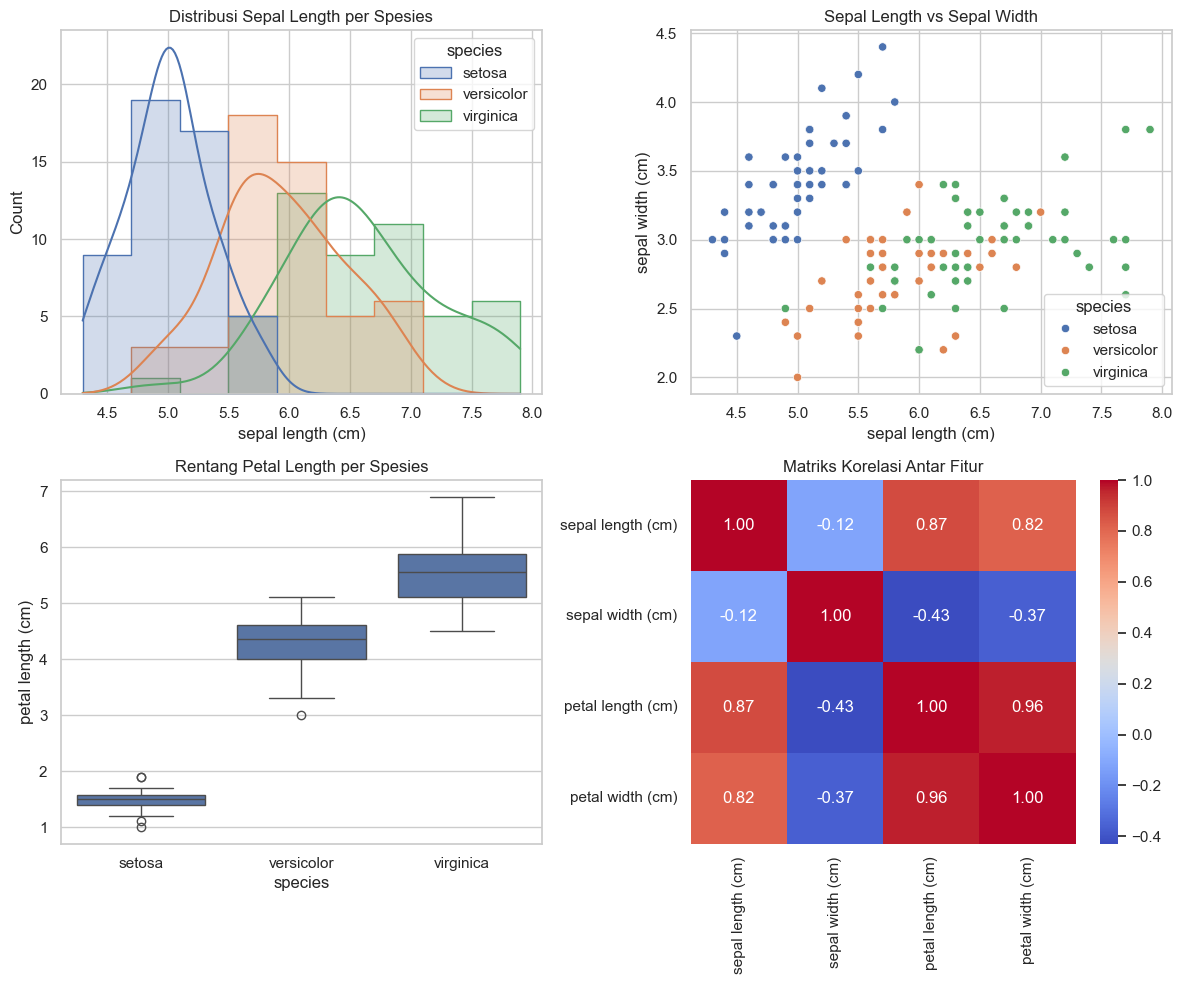

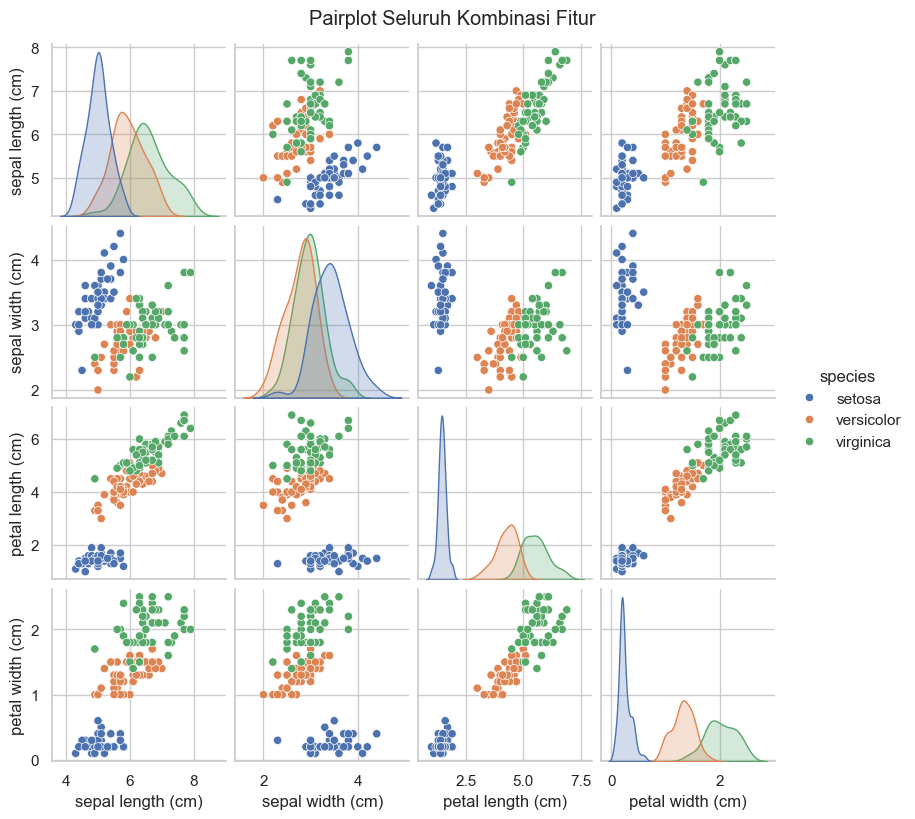

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

sns.set(style="whitegrid")

# 1. Memuat dataset ke dalam Pandas DataFrame
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in iris.target]

# =========================================================
# ANALISIS STATISTIK DESKRIPTIF (TEKSTUAL)
# =========================================================

print("=== 1. Dimensi Data (Baris, Kolom) ===")
print(df.shape)
print("\n")

print("=== 2. Informasi Tipe Data & Missing Values ===")
print(df.info())
print("\n")

print("=== 3. Cek Jumlah Data yang Kosong (Missing Values) ===")
print(df.isnull().sum())
print("\n")

print("=== 4. Ringkasan Statistik (Mean, Median, Min, Max) ===")
print(df.describe())
print("\n")

print("=== 5. Distribusi Jumlah Data Per Target/Spesies ===")
print(df['species'].value_counts())

# =========================================================
# VISUALISASI DATA (GRAFIK)
# =========================================================

# Membuat jendela plot baru
plt.figure(figsize=(12, 10))

# Grafik 1: Distribusi salah satu fitur (Histogram & KDE)
plt.subplot(2, 2, 1)
sns.histplot(data=df, x='sepal length (cm)', hue='species', kde=True, element='step')
plt.title('Distribusi Sepal Length per Spesies')

# Grafik 2: Hubungan antara 2 fitur (Scatter Plot)
plt.subplot(2, 2, 2)
sns.scatterplot(data=df, x='sepal length (cm)', y='sepal width (cm)', hue='species')
plt.title('Sepal Length vs Sepal Width')

# Grafik 3: Deteksi Outlier (Box Plot)
plt.subplot(2, 2, 3)
sns.boxplot(data=df, x='species', y='petal length (cm)')
plt.title('Rentang Petal Length per Spesies')

# Grafik 4: Matriks Korelasi (Heatmap)
# Menghitung korelasi hanya untuk kolom numerik
plt.subplot(2, 2, 4)
numerical_df = df.drop(columns=['species'])
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Antar Fitur')

# Menampilkan semua grafik sekaligus
plt.tight_layout()
plt.show()

# Grafik Tambahan yang Sangat Populer untuk EDA: Pairplot
# Melihat hubungan semua kombinasi fitur sekaligus
sns.pairplot(df, hue='species', height=2)
plt.suptitle("Pairplot Seluruh Kombinasi Fitur", y=1.02)
plt.show()


## Baca Dataset

In [7]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


## INFORMASI DATASET

In [8]:
df.describe(include="all")

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


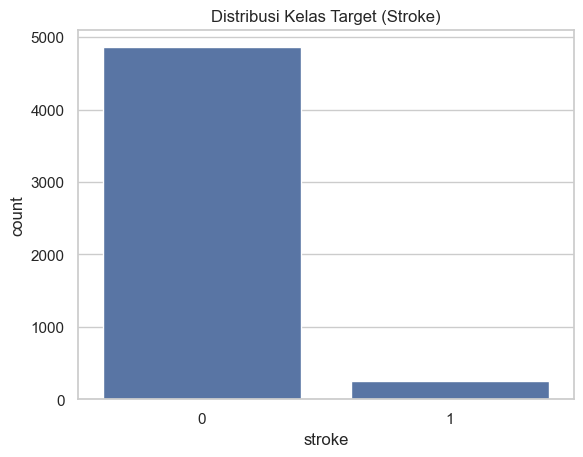

In [9]:
sns.countplot(x="stroke",data=df)
plt.title("Distribusi Kelas Target (Stroke)")
plt.show()

In [18]:
categorical_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
for col in categorical_cols:
    df[col] = df[col].astype("category")

df.dtypes

id                      int64
gender               category
age                   float64
hypertension            int64
heart_disease           int64
ever_married         category
work_type            category
Residence_type       category
avg_glucose_level     float64
bmi                   float64
smoking_status       category
stroke                  int64
dtype: object

In [19]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [25]:
df["bmi"].fillna(df["bmi"].median(), inplace=True)

Jumlah missing values di kolom BMI: 0

Tampilan data BMI saat ini:
    bmi
0  36.6
1  28.1
2  32.5
3  34.4
4  24.0


In [23]:
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

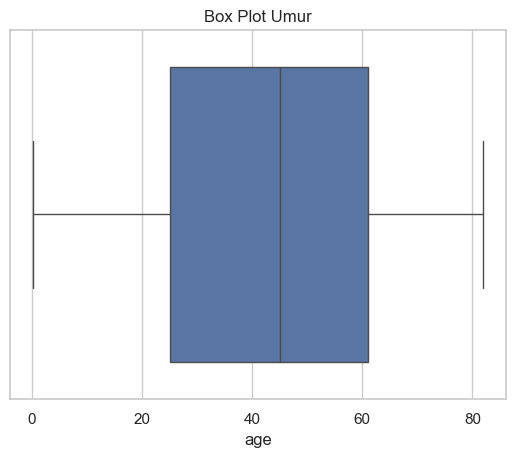

In [24]:
sns.boxplot(x=df["age"])
plt.title("Box Plot Umur")
plt.show()

In [31]:
Q1 = df["age"].quantile(.25)
Q3 = df["age"].quantile(0.75)

IQR = Q3 - Q1
outliers = df[
    (df["age"] < Q1 - 1.5*IQR) |
    (df["age"] > Q3 + 1.5*IQR)
     ]

print("Jumlah Outlier umur: ", len(outliers))

Jumlah Outlier umur:  0


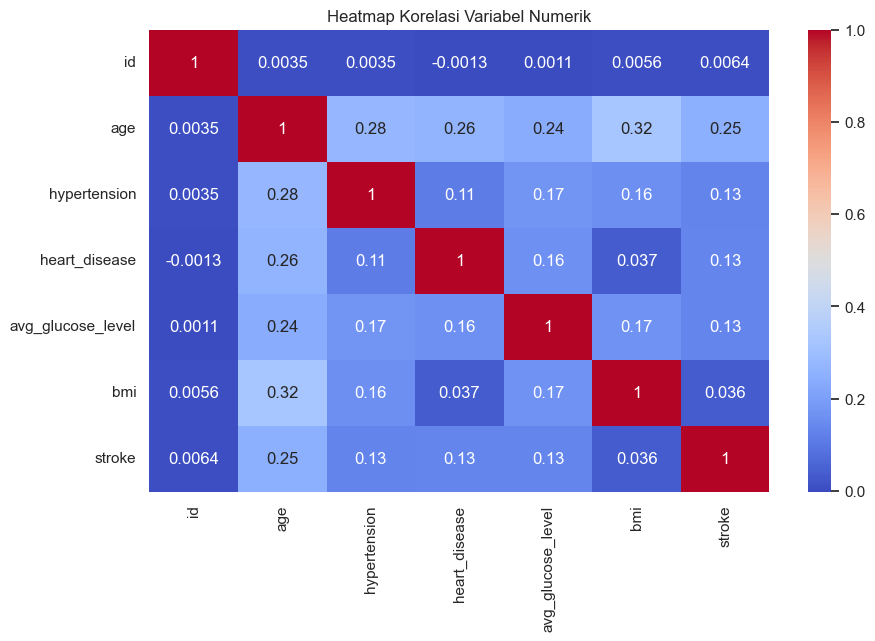

In [32]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(10,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Heatmap Korelasi Variabel Numerik")
plt.show()

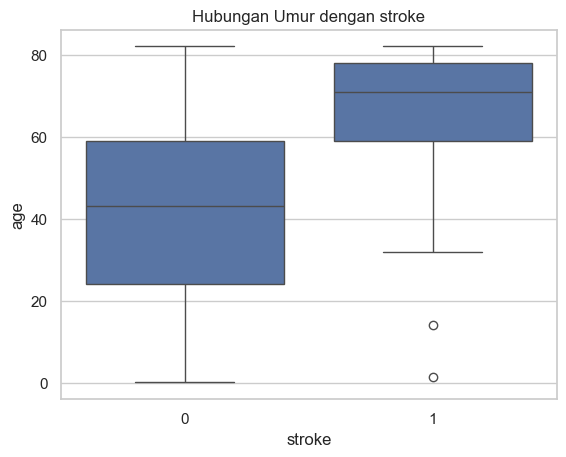

In [33]:
sns.boxplot(x="stroke", y="age", data=df)
plt.title("Hubungan Umur dengan stroke")
plt.show()

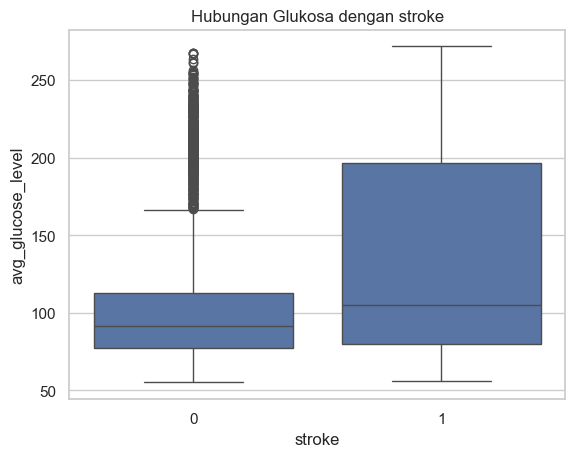

In [34]:
sns.boxplot(
    x="stroke", y="avg_glucose_level", data=df)
plt.title("Hubungan Glukosa dengan stroke")
plt.show()